# 05 — Feature Attribution in Transformer MLMs: Attention Rollup vs. Integrated Gradients
### Stage 5: Explainable AI Foundations for Pretrained Masked Language Models

---

## Executive Overview

Understanding *why* a language model makes a specific prediction is essential for reliable deployment. In masked language models, we seek to answer:
> **Which context words in a Hindi sentence contributed most strongly to the model predicting the target token?**

In this stage, we implement and compare two fundamental feature attribution methods:
1. **Self-Attention Attribution**: Extracted from the Transformer's multi-head attention weights (last-layer mean over heads).
2. **Integrated Gradients (IG)**: Path-integral of gradients computed from a baseline embedding (Sundararajan et al., ICML 2017).

We also examine:
- Subword-to-word attribution aggregation for Devanagari script.
- The fundamental **discrete-continuous mismatch** of Integrated Gradients when applied to masked language models.

In [1]:
import sys
from pathlib import Path
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoModelForMaskedLM, AutoTokenizer

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.explanations.hindi_explanations import (
    prepare_masked_target_input,
    extract_mlm_attention,
    extract_mlm_integrated_gradients,
)

print("Hindi explanation module loaded.")

Hindi explanation module loaded.


---

## 1. Feature Attribution Formulations for Masked Language Models

### A. Attention Attribution (Last-Layer Head Mean)
In a Transformer with $L$ layers and $H$ attention heads, the attention weight from target position $t$ to context position $j$ in head $h$ of the final layer $L$ is:
$$A_{t, j} = rac{1}{H} \sum_{h=1}^H 	ext{Attention}_{L, h}[t, j]$$
Attentions naturally sum to 1 over context tokens due to the softmax operation.

### B. Integrated Gradients (Path-Integral Attribution)
Integrated Gradients computes the attribution of feature $j$ along the straight-line path from a neutral baseline embedding $x'$ (all zeros) to the input embedding $x$:
$$	ext{IG}_j(x) = (x_j - x'_j) 	imes \int_{0}^1 rac{\partial F(x' + lpha (x - x'))}{\partial x_j} dlpha$$
Approximated via $m$-step Gauss-Legendre quadrature (default $m = 20$). The resulting vector is reduced to a scalar via L2-norm or sum.

---

## 2. Interactive Attribution Playground on Hindi Sentences

Let's run a live attribution comparison on a sample Hindi sentence:
`"राम और सीता साथ हैं।"` with target word `"सीता"`.

In [2]:
MODEL_NAME = "google/muril-base-cased"
print(f"Loading {MODEL_NAME} for attribution demo...")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
model = AutoModelForMaskedLM.from_pretrained(MODEL_NAME).to(device)
model.eval()

sentence = "राम और सीता साथ हैं।"
target_word = "सीता"

# Prepare masked target input
prep = prepare_masked_target_input(sentence, target_word, tokenizer, device=device)
print(f"Original Text:   {sentence}")
print(f"Target Word:     {target_word}")
print(f"Eligible:        {prep['is_eligible']}")
print(f"Tokens:          {prep['tokens']}")
print(f"Content Tokens:  {prep['content_tokens']}")

Loading google/muril-base-cased for attribution demo...


Some weights of the model checkpoint at google/muril-base-cased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Original Text:   राम और सीता साथ हैं।
Target Word:     सीता
Eligible:        True
Tokens:          ['[CLS]', 'राम', 'और', 'सीता', 'साथ', 'हैं', '।', '[SEP]']
Content Tokens:  ['राम', 'और', 'सीता', 'साथ', 'हैं', '।']


In [3]:
# Extract Attention Attribution
attn_res = extract_mlm_attention(
    model=model,
    masked_input_ids=prep["masked_input_ids"],
    attention_mask=prep["attention_mask"],
    target_pos=prep["target_pos"],
    target_token_id=prep["target_token_id"],
    content_indices=prep["content_indices"],
)
attn_attr = attn_res["attention_scores"]

# Extract Integrated Gradients Attribution
ig_res = extract_mlm_integrated_gradients(
    model=model,
    tokenizer=tokenizer,
    masked_input_ids=prep["masked_input_ids"],
    attention_mask=prep["attention_mask"],
    target_pos=prep["target_pos"],
    target_token_id=prep["target_token_id"],
    content_indices=prep["content_indices"],
    n_steps=15,
)
ig_attr = ig_res["ig_abs"]

tokens = prep["content_tokens"]
print("Content Token Attribution Scores:")
df_attr_demo = pd.DataFrame({
    "Content_Token": tokens,
    "Attention": [f"{s:.4f}" for s in attn_attr],
    "Integrated_Gradients": [f"{s:.4f}" for s in ig_attr],
})
df_attr_demo

BertSdpaSelfAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embedding_type` or `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


Content Token Attribution Scores:


,Content_Token,Attention,Integrated_Gradients
0,राम,0.3569,7.7095
1,और,0.1572,6.2503
2,सीता,0.0832,0.0000
3,साथ,0.1115,6.4769
4,हैं,0.0915,6.5697
5,।,0.1996,6.1776


C:\Users\Aneka\AppData\Local\Temp\ipykernel_14564\1741919681.py:16: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Aneka\AppData\Local\Temp\ipykernel_14564\1741919681.py:16: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Aneka\AppData\Local\Temp\ipykernel_14564\1741919681.py:16: UserWarning: Glyph 2324 (\N{DEVANAGARI LETTER AU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Aneka\AppData\Local\Temp\ipykernel_14564\1741919681.py:16: UserWarning: Glyph 2360 (\N{DEVANAGARI LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Aneka\AppData\Local\Temp\ipykernel_14564\1741919681.py:16: UserWarning: Glyph 2340 (\N{DEVANAGARI LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Aneka\AppData\Local\Temp\ipykernel_14564\1741919681.py:16: UserWarning: Glyph 2341 (\N{DEVANAGARI LETTER THA}) missing fr

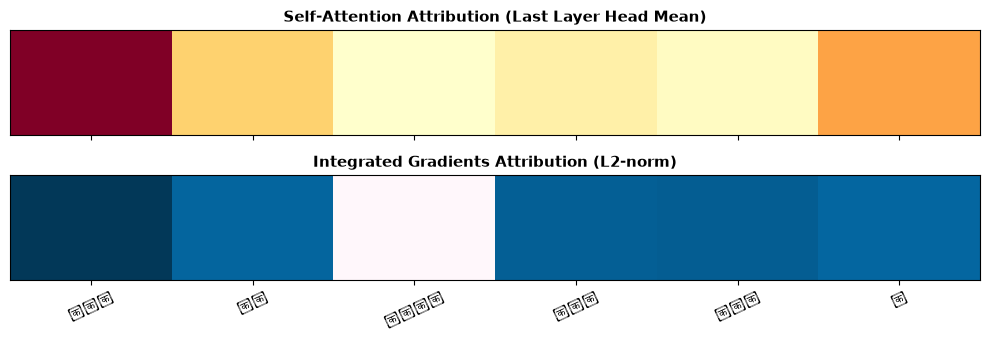

In [4]:
# Visualizing Attribution Heatmaps
fig, axes = plt.subplots(2, 1, figsize=(10, 3.5), sharex=True)

# Attention Heatmap
axes[0].imshow([attn_attr], cmap="YlOrRd", aspect="auto")
axes[0].set_yticks([])
axes[0].set_title("Self-Attention Attribution (Last Layer Head Mean)", fontsize=11, fontweight="bold")

# IG Heatmap
axes[1].imshow([ig_attr], cmap="PuBu", aspect="auto")
axes[1].set_yticks([])
axes[1].set_title("Integrated Gradients Attribution (L2-norm)", fontsize=11, fontweight="bold")
axes[1].set_xticks(range(len(tokens)))
axes[1].set_xticklabels(tokens, fontsize=10, rotation=25)

plt.tight_layout()
plt.show()

In [5]:
# Clean up model
del model
del tokenizer
torch.cuda.empty_cache() if torch.cuda.is_available() else None
print("Model memory released.")

Model memory released.


---

## 3. The Continuous-to-Discrete Domain Mismatch of Integrated Gradients

An important theoretical consideration in explainable NLP:
- **Integrated Gradients** was developed for continuous input domains (e.g. image pixels).
- In NLP, embeddings are continuous, but the underlying tokens are **strictly discrete points** in high-dimensional space.
- The path integral interpolates through ungrounded points in embedding space that do not correspond to any valid subwords.
- When evaluating discrete token removal interventions (e.g. replacing tokens with `[MASK]`), continuous gradient approximations often fail to align with actual token impact.

We will empirically test this mismatch in the next notebook using rigorous **faithfulness intervention evaluation**!

---

## Stage 5 Summary & Next Step

-  Implemented Attention Rollup and Integrated Gradients feature attribution for masked language models.
-  Verified subword-to-word alignment and Devanagari attribution mapping.
-  Identified the theoretical challenge of continuous gradient integration in discrete token spaces.

**Next Notebook**: In [06_explanation_stability_and_faithfulness.ipynb](06_explanation_stability_and_faithfulness.ipynb), we address the core scientific question of the paper: **Does explanation stability under spelling noise predict explanation faithfulness?**